# QAOA on Net1: depth 1 vs depth 2, X vs XY mixer

Compares the saved QAOA runs for k = 3 on both formulations (topological, leak):

In [ ]:
import json, glob, os, sys
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")          # run everything from the repo root
sys.path.append(".")

DATA_DIR = "results/solutions"
FORMULATIONS = ["topological", "leak"]
ORDER = ["p1 X", "p2 X", "p1 XY", "p2 XY"]
COLORS = {"p1 X": "#9aa5b1", "p2 X": "#3b82f6", "p1 XY": "#318b3d", "p2 XY": "#f59e0b"}
NETWORK = "Net1"
K = 3
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [30]:
def label(run):
    p = run["params"]
    return f"p{p['reps']} {p.get('mixer', 'x').upper()}"   # the p1 files have no mixer key -> X

runs = {}
for form in FORMULATIONS:
    for path in glob.glob(os.path.join(DATA_DIR, f"{NETWORK}_{form}_qaoa*_k{K}.json")):
        run = json.load(open(path))
        runs[(form, label(run))] = run

missing = [(f, l) for f in FORMULATIONS for l in ORDER if (f, l) not in runs]
print("loaded:", sorted(runs))
if missing:
    print("MISSING:", missing)

def gurobi_ref(form):
    p = os.path.join(DATA_DIR, f"{NETWORK}_{form}_gurobi_k{K}.json")
    return json.load(open(p))["energy"] if os.path.exists(p) else None

loaded: [('leak', 'p1 X'), ('leak', 'p1 XY'), ('leak', 'p2 X'), ('leak', 'p2 XY'), ('topological', 'p1 X'), ('topological', 'p1 XY'), ('topological', 'p2 X'), ('topological', 'p2 XY')]


## Summary table


In [31]:
rows = []
for (form, lab), r in runs.items():
    s = pd.DataFrame({"sensors": [tuple(sorted(x)) for x in r["samples"]], "energy": r["sample_energies"]})
    s["feasible"] = s.sensors.map(len) == K
    feas = s[s.feasible]
    rows.append(dict(
        formulation=form, config=lab,
        best_energy=r["energy"],
        best_placement=" ".join(r["sensors"]),
        feasible_pct=100 * s.feasible.mean(),
        mean_feasible_energy=feas.energy.mean() if len(feas) else np.nan,
        unique_placements=s.sensors.nunique(),
        hit_best_pct=100 * (s.energy <= r["energy"] + 1e-9).mean(),
        runtime_s=r["runtime_s"],
    ))
summary = pd.DataFrame(rows)
summary["config"] = pd.Categorical(summary.config, ORDER, ordered=True)
summary = summary.sort_values(["formulation", "config"]).reset_index(drop=True)
summary.round(3)

,formulation,config,best_energy,best_placement,feasible_pct,mean_feasible_energy,unique_placements,hit_best_pct,runtime_s
0,leak,p1 X,0.750,11 12 23,47.266,4.677,204,1.953,45.383
1,leak,p2 X,1.250,11 12 22,26.562,6.318,174,1.953,57.952
2,leak,p1 XY,0.750,10 12 23,100.000,3.387,66,4.492,7.914
3,leak,p2 XY,0.750,11 12 23,100.000,3.859,68,7.227,15.944
4,topological,p1 X,1.791,11 12 22,36.719,3.884,255,0.586,41.625
5,topological,p2 X,1.791,11 12 22,44.922,3.715,232,0.195,58.969
6,topological,p1 XY,1.791,11 12 22,100.000,3.760,67,0.195,5.233
7,topological,p2 XY,2.208,11 13 22,100.000,3.607,75,2.344,15.001


## Best energy, feasibility and runtime

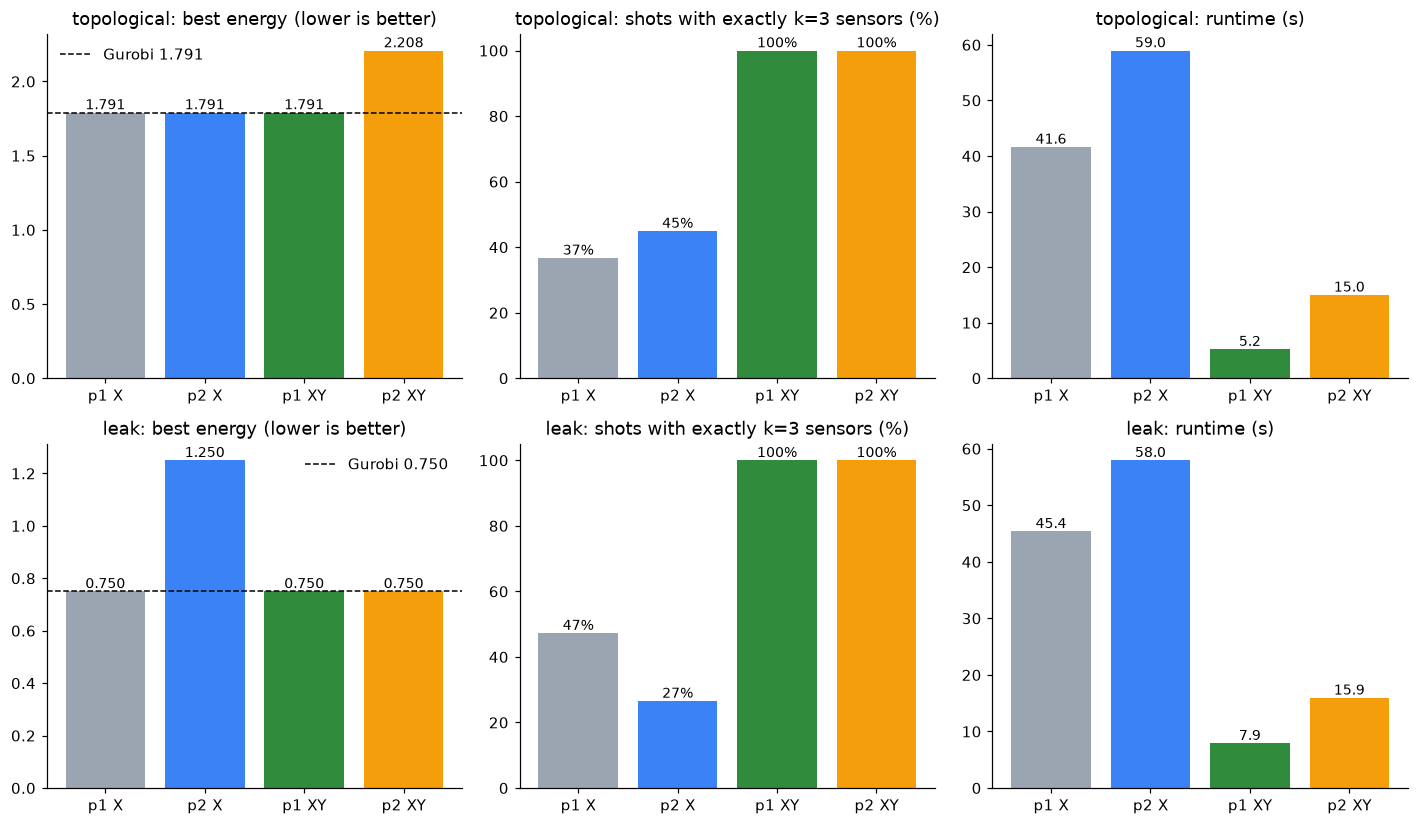

In [32]:
fig, axes = plt.subplots(len(FORMULATIONS), 3, figsize=(13, 3.8 * len(FORMULATIONS)))
for i, form in enumerate(FORMULATIONS):
    d = summary[summary.formulation == form].set_index("config").reindex(ORDER)
    cols = [COLORS[c] for c in ORDER]
    ref = gurobi_ref(form)

    ax = axes[i, 0]
    ax.bar(ORDER, d.best_energy, color=cols)
    if ref is not None:
        ax.axhline(ref, color="k", ls="--", lw=1, label=f"Gurobi {ref:.3f}"); ax.legend(frameon=False)
    ax.set_title(f"{form}: best energy (lower is better)")
    for x, v in enumerate(d.best_energy): ax.text(x, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)

    ax = axes[i, 1]
    ax.bar(ORDER, d.feasible_pct, color=cols)
    ax.set_ylim(0, 105); ax.set_title(f"{form}: shots with exactly k={K} sensors (%)")
    for x, v in enumerate(d.feasible_pct): ax.text(x, v + 1, f"{v:.0f}%", ha="center", fontsize=9)

    ax = axes[i, 2]
    ax.bar(ORDER, d.runtime_s, color=cols)
    ax.set_title(f"{form}: runtime (s)")
    for x, v in enumerate(d.runtime_s): ax.text(x, v, f"{v:.1f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.show()